<a href="https://colab.research.google.com/github/Irene-sketch/AI_ML_sem5/blob/main/logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 6. Logistic Regression with a Dataset with Fewer Features (Iris Dataset)

Now, let's demonstrate the same process using a dataset with fewer features. We'll use the `load_iris` dataset from `sklearn`, which has 4 features. The steps will be identical: load data, split, train model, evaluate, and create a prediction UI.

#### 6.1. Load Iris Dataset

Loading the Iris dataset, which is a multi-class classification problem but can be adapted for binary if needed, or we can use a multi-class logistic regression. For simplicity, we'll keep it as a multi-class classification as Logistic Regression supports it natively.

In [ ]:
from sklearn.datasets import load_iris

# Load the Iris dataset
iris = load_iris()
X_iris = pd.DataFrame(iris.data, columns=iris.feature_names)
y_iris = pd.Series(iris.target)

print("Iris Features (X_iris) shape:", X_iris.shape)
print("Iris Target (y_iris) shape:", y_iris.shape)

# Display the first 5 rows of the Iris features
display(X_iris.head())

Iris Features (X_iris) shape: (150, 4)
Iris Target (y_iris) shape: (150,)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


#### 6.2. Split Iris Data into Training and Testing Sets

In [ ]:
# Split the Iris dataset into training and testing sets
X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(X_iris, y_iris, test_size=0.2, random_state=30)

print("X_train_iris shape:", X_train_iris.shape)
print("X_test_iris shape:", X_test_iris.shape)
print("y_train_iris shape:", y_train_iris.shape)
print("y_test_iris shape:", y_test_iris.shape)

X_train_iris shape: (120, 4)
X_test_iris shape: (30, 4)
y_train_iris shape: (120,)
y_test_iris shape: (30,)


#### 6.3. Train a Logistic Regression Model for Iris

In [ ]:
# Initialize and train a Logistic Regression model for Iris
model_iris = LogisticRegression(max_iter=200, random_state=22)
model_iris.fit(X_train_iris, y_train_iris)

print("Iris model training complete.")

Iris model training complete.


#### 6.4. Make Predictions and Analyze Performance for Iris Model

In [ ]:
# Make predictions on the Iris test set
y_pred_iris = model_iris.predict(X_test_iris)

# Calculate accuracy
accuracy_iris = accuracy_score(y_test_iris, y_pred_iris)
print(f"Iris Model Accuracy: {accuracy_iris:.2%}") # Display as percentage

# Display classification report
print("\nIris Model Classification Report:")
print(classification_report(y_test_iris, y_pred_iris, target_names=iris.target_names))

Iris Model Accuracy: 96.67%

Iris Model Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       1.00      0.89      0.94         9
   virginica       0.90      1.00      0.95         9

    accuracy                           0.97        30
   macro avg       0.97      0.96      0.96        30
weighted avg       0.97      0.97      0.97        30



### 6.6. Iris Model Confusion Matrix Visualization

This heatmap provides a visual representation of the Iris model's performance, showing how many samples from each actual class were predicted into each class.

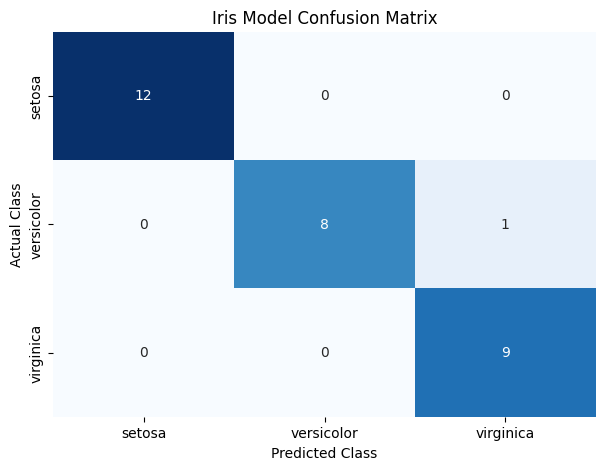

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate the confusion matrix for the Iris model
cm_iris = confusion_matrix(y_test_iris, y_pred_iris)

# Plot the confusion matrix as a heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(cm_iris, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title('Iris Model Confusion Matrix')
plt.show()

#### 6.5. Create a User Interface for Iris Prediction

This UI will allow users to input values for the 4 Iris features and get a prediction from the trained `model_iris`.

In [ ]:
from matplotlib.colors import ListedColormap

# For visualization, we'll use two features: petal length and petal width
X_viz = X_iris[['petal length (cm)', 'petal width (cm)']]
y_viz = y_iris

# Train a new model on only these two features for visualization purposes
# This model is specifically for the 2D plot, not the main model_iris
model_viz = LogisticRegression(max_iter=200, random_state=22)
model_viz.fit(X_viz, y_viz)

# Create input widgets for each Iris feature
input_widgets_iris = []
for feature_name in iris.feature_names:
    input_widgets_iris.append(FloatText(
        value=X_iris[feature_name].mean(), # Pre-fill with mean value as a sensible default
        description=f'{feature_name}:',
        disabled=False,
        layout=Layout(width='300px')
    ))

# Create a button to trigger prediction
predict_button_iris = Button(description="Predict Iris")

# Create an output widget to display Iris predictions and the plot
output_area_iris = Output()

def on_predict_button_iris_clicked(b):
    with output_area_iris:
        clear_output()
        try:
            # Get values from input widgets
            user_input_values_iris = [widget.value for widget in input_widgets_iris]

            # Convert to numpy array and reshape for prediction
            user_data_iris = np.array(user_input_values_iris).reshape(1, -1)

            # Make prediction using the main model_iris (all 4 features)
            prediction_iris = model_iris.predict(user_data_iris)
            prediction_proba_iris = model_iris.predict_proba(user_data_iris)

            # Display results
            predicted_class_name_iris = iris.target_names[prediction_iris[0]]
            print(f"Predicted Iris Class: {predicted_class_name_iris}")
            print(f"Probabilities for each class: {prediction_proba_iris[0]}")
            print(f"Class names: {list(iris.target_names)}")

            # --- Generate and display the classification plot ---
            # Create color maps for the plot
            cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
            cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

            # Determine the min and max values for the features to define the mesh grid
            x_min, x_max = X_viz.iloc[:, 0].min() - 0.5, X_viz.iloc[:, 0].max() + 0.5
            y_min, y_max = X_viz.iloc[:, 1].min() - 0.5, X_viz.iloc[:, 1].max() + 0.5
            h = 0.02 # step size in the mesh
            xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                                 np.arange(y_min, y_max, h))

            # Predict class for each point in the mesh grid using model_viz (2 features)
            Z = model_viz.predict(np.c_[xx.ravel(), yy.ravel()])

            # Put the result into a color plot
            Z = Z.reshape(xx.shape)

            plt.figure(figsize=(10, 7))
            plt.pcolormesh(xx, yy, Z, cmap=cmap_light, shading='auto')

            # Plot also the training points
            sns.scatterplot(
                x=X_viz.iloc[:, 0],
                y=X_viz.iloc[:, 1],
                hue=iris.target_names[y_viz],
                palette=cmap_bold.colors,
                alpha=1.0,
                edgecolor="black",
                s=100,
                zorder=10
            )

            # Get the petal length and petal width from the user's input for plotting
            petal_length_idx = iris.feature_names.index('petal length (cm)')
            petal_width_idx = iris.feature_names.index('petal width (cm)')
            user_petal_length = user_data_iris[0, petal_length_idx]
            user_petal_width = user_data_iris[0, petal_width_idx]

            # Plot the user's input point
            plt.scatter(user_petal_length, user_petal_width,
                        marker='*', s=300, color='gold', edgecolor='black',
                        label=f'Your Input ({predicted_class_name_iris})', zorder=11)

            plt.xlabel('Petal Length (cm)')
            plt.ylabel('Petal Width (cm)')
            plt.title('Logistic Regression Decision Boundaries on Iris Dataset (Petal Length vs. Petal Width)')
            plt.xlim(xx.min(), xx.max())
            plt.ylim(yy.min(), yy.max())
            plt.legend()
            plt.show()

        except Exception as e:
            print(f"An error occurred: {e}")

# Attach the click event handler to the button
predict_button_iris.on_click(on_predict_button_iris_clicked)

# Arrange widgets in a VBox or HBox
num_cols_iris = 2 # Number of columns for input fields
input_rows_iris = []
for i in range(0, len(input_widgets_iris), num_cols_iris):
    input_rows_iris.append(HBox(input_widgets_iris[i:i+num_cols_iris]))

ui_iris = VBox([
    Label('Enter Iris feature values for prediction:'),
    VBox(input_rows_iris),
    predict_button_iris,
    output_area_iris
])

display(ui_iris)